In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("CarPrice_Assignment.csv")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(df.isnull().sum())

Number of rows: 205
Number of columns: 26
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [5]:
print(df.info())
print("Number of duplicate rows:", df.duplicated().sum())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

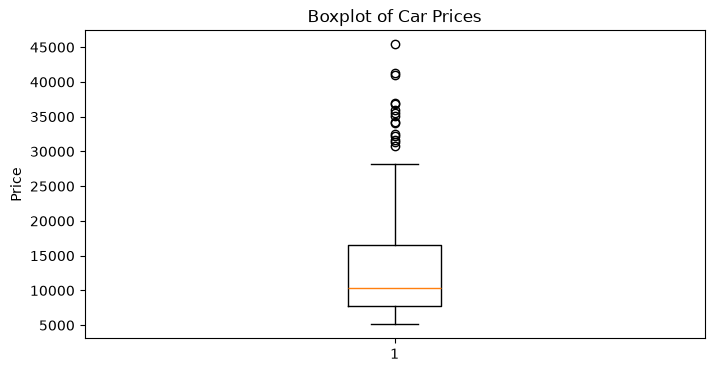

In [6]:
#to detect outliers
plt.figure(figsize=(8, 4))
plt.boxplot(df['price'])
plt.ylabel("Price")
plt.title("Boxplot of Car Prices")

plt.show()

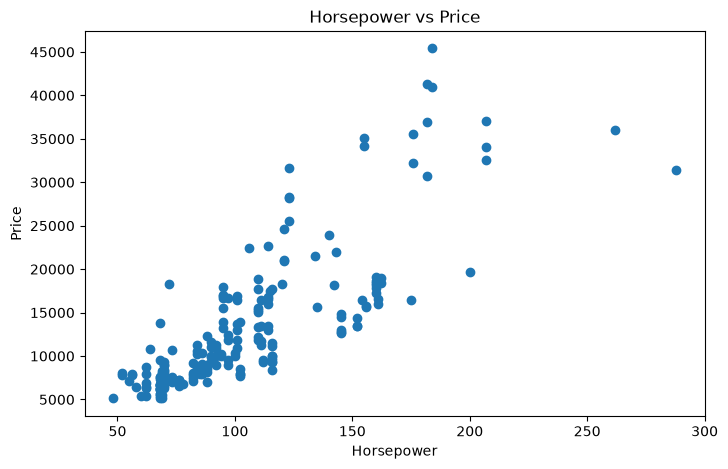

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(df['horsepower'], df['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("Horsepower vs Price")

plt.show()

In [8]:
features = [
    'wheelbase',
    'carlength',
    'carwidth',
    'carheight',
    'curbweight',
    'enginesize',
    'boreratio',
    'stroke',
    'compressionratio',
    'horsepower',
    'peakrpm',
    'citympg',
    'highwaympg'
]

X = df[features].values
y = df['price'].values

In [9]:
np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 164
Testing samples: 41


In [10]:
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [11]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0

    for i in range(m):
        f = np.dot(X[i], w) + b
        error = f - y[i]
        cost += error ** 2

    cost = cost / (2 * m)

    return cost

In [12]:
def gradient_descent(X, y, w, b, alpha, iterations):
    m = X.shape[0]
    cost_history = []

    for i in range(iterations):

        dj_dw = np.zeros(len(w))
        dj_db = 0

        for j in range(m):

            f = np.dot(X[j], w) + b
            error = f - y[j]

            for k in range(len(w)):
                dj_dw[k] += error * X[j][k]

            dj_db += error

        for k in range(len(w)):
            dj_dw[k] = dj_dw[k] / m

        dj_db = dj_db / m

        for k in range(len(w)):
            w[k] = w[k] - alpha * dj_dw[k]

        b = b - alpha * dj_db

        cost_history.append(compute_cost(X, y, w, b))

    return w, b, cost_history

In [13]:
w = np.zeros(X_train.shape[1])
b = 0

alpha = 0.01
iterations = 10000

print("Number of weights:", len(w))
print("Initial bias:", b)

Number of weights: 13
Initial bias: 0


In [14]:
w, b, cost_history = gradient_descent(
    X_train,
    y_train,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Training complete


In [15]:
y_pred = np.zeros(len(X_test))

for i in range(len(X_test)):
    y_pred[i] = np.dot(X_test[i], w) + b

In [16]:
mae = np.mean(np.abs(y_test - y_pred))

mse = np.mean((y_test - y_pred) ** 2)

rmse = np.sqrt(mse)

ss_res = np.sum((y_test - y_pred) ** 2)

ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print("MODEL PERFORMANCE")
print("-----------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

print("INTERCEPT:", b)

print("\nWEIGHTS")
print("-------")

for i in range(len(features)):
    print(features[i], ":", w[i])

MODEL PERFORMANCE
-----------------
MAE : 2932.61906982355
MSE : 15153071.44917532
RMSE: 3892.694625728471
R²  : 0.8045844950007667
INTERCEPT: 12975.610774390154

WEIGHTS
-------
wheelbase : 537.5506288382705
carlength : -976.7228654348921
carwidth : 952.066519560496
carheight : 666.3562579129455
curbweight : 1246.690591921044
enginesize : 4121.084019301811
boreratio : -436.72523072025336
stroke : -908.7942690267964
compressionratio : 1260.2921808850613
horsepower : 2207.677376825829
peakrpm : 1150.9213588524794
citympg : -2211.8123188751006
highwaympg : 2152.1292885878725


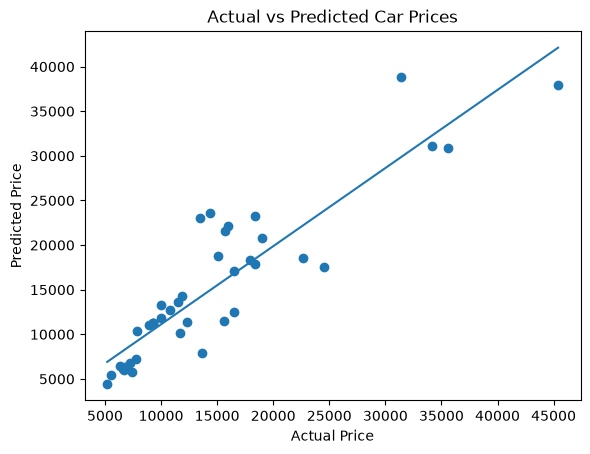

In [18]:
plt.scatter(y_test, y_pred)

m, c = np.polyfit(y_test, y_pred, 1)

x_line = np.linspace(y_test.min(), y_test.max(), 100)
y_line = m * x_line + c

plt.plot(x_line, y_line)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

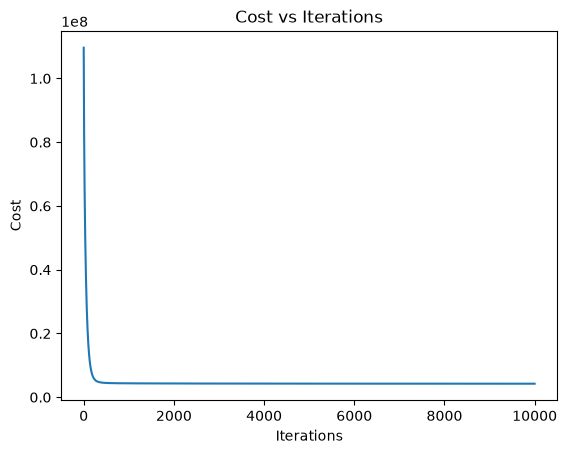

In [ ]:
plt.plot(range(iterations), cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")
plt.show()